# Conclusiones: comparación de modelos, ganador y evaluación en test

**Proyecto:** clasificación multiclase de la *utilidad para la conservación del suelo* de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #42 (subtareas #64 y #65) · **Notebook:** `06_conclusiones.ipynb` · **Responsable:** todo el equipo

Hasta aquí cada integrante entrenó un algoritmo en su notebook (`02` a `05`). Todos usaron los mismos datos, las mismas validaciones y la misma evaluación de `comun.py`. Cada uno dejó dos ficheros:

- `models/<notebook>.joblib`: el pipeline completo (preprocesado + modelo);
- `resultados/<notebook>.json`: sus cifras en validación.

En este notebook:

1. **Comparamos** los cuatro modelos y el Dummy con esas cifras, sin reentrenar nada.
2. **Elegimos el ganador** con la regla del equipo (`docs/acuerdos.md`): el de **mayor F1 macro en toda la validación** entre los que tienen un **gap menor de 5 puntos**.
3. **Evaluamos el ganador en test**, una sola vez. Es la nota final: con ella no se cambia de modelo.
4. Analizamos sus errores, si rinde igual en todos los sitios y en qué variables se apoya.
5. Comprobamos los requisitos del Nivel Esencial y sacamos las conclusiones para negocio.

Cada paso tiene **Qué hacemos**, **Por qué** y **Cómo leer el resultado**, como en los notebooks de los modelos. Los números de los apartados «Qué vemos» corresponden a la última ejecución.

## Paso 1: cargar los resultados de los cuatro modelos

**Qué hacemos:** `cargar_resultados()` de `comun.py` lee todos los `resultados/*.json` y los devuelve en una tabla. También leemos los JSON completos: traen el detalle por clase y la accuracy.

**Por qué:** comparamos lo que cada notebook ya midió en validación. Reentrenar aquí podría dar cifras distintas y nadie sabría cuáles valen.

**Cómo leer el resultado:** una fila por modelo. `cargar_resultados()` ya las ordena con la regla del ganador: primero los que cumplen el gap y, entre ellos, de mayor a menor F1 en toda la validación.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Librería común del equipo: mismas reglas para comparar y evaluar
from comun import (
    CLASES,
    DATOS,
    GAP_MAXIMO,
    MODELOS,
    RESULTADOS,
    baseline_dummy,
    cargar_datos,
    cargar_resultados,
    dibujar_matriz,
    errores_frecuentes,
    importancia_permutacion,
    nivel_gap,
    por_clase,
    predecir_con_regla,
    separar_xy,
    sin_medidas,
)

NOMBRES = {
    "02_regresion_logistica": "Regresión logística",
    "03_arbol_decision": "Árbol de decisión",
    "04_svm": "SVM",
    "05_knn": "KNN",
}


def metricas(y, pred):
    """F1 macro y accuracy de unas predicciones (test y comparaciones)."""
    return {
        "F1 macro": f1_score(y, pred, average="macro"),
        "accuracy": accuracy_score(y, pred),
        "accuracy balanceada": balanced_accuracy_score(y, pred),
    }


resultados = cargar_resultados()  # ya ordenados con la regla del ganador
detalle = {
    ruta.stem: json.loads(ruta.read_text(encoding="utf-8"))
    for ruta in sorted(RESULTADOS.glob("*.json"))
}
print(f"Modelos con resultados: {len(resultados)}")
resultados.round(3)

Modelos con resultados: 4


,f1_cv,desv_cv,f1_cv_sitio,f1_train,f1_val,f1_val_medidas,gap,cumple_gap
modelo,,,,,,,,
04_svm,0.582,0.085,0.507,0.631,0.636,0.601,3.024,True
03_arbol_decision,0.565,0.025,0.519,0.557,0.562,0.520,3.611,True
05_knn,0.533,0.046,0.492,0.578,0.552,0.524,5.351,False
02_regresion_logistica,0.434,0.021,0.397,0.494,0.468,0.429,6.523,False


## Paso 2: el Dummy, la referencia común

**Qué hacemos:** volvemos a calcular el Dummy con `baseline_dummy()`. Es un modelo que responde siempre la clase más frecuente (`good`) y `none` a las parcelas sin medidas. Usa `data/train.csv` y `data/val.csv`, que lee `cargar_datos()`.

**Por qué:** un modelo solo sirve si supera claramente a esta respuesta fija. El cálculo es el mismo en todos los notebooks, así que sale lo mismo que en ellos.

**Cómo leer el resultado:** el F1 macro del Dummy en CV, en toda la validación y solo en las parcelas con medidas.

In [2]:
train, val = (
    cargar_datos()
)  # train y validación (el test se lee más abajo, una sola vez)
X_train, y_train = separar_xy(train)
X_val, y_val = separar_xy(val)

f1_dummy = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## Paso 3: tabla comparativa (subtarea #64)

**Qué hacemos:** juntamos en una tabla, para cada modelo, todo lo que pide la historia #42:

| Columna | Qué es |
|---|---|
| F1 val (toda) | F1 macro en las 110 parcelas de validación, con la regla `none`. **Es la métrica que elige al ganador.** |
| F1 val (con medidas) | F1 macro solo en las parcelas que pasan por el modelo. |
| accuracy val (toda / con medidas) | Proporción de aciertos. Se da porque la pide el enunciado, pero no decide: con clases desbalanceadas engaña (guía, error 2). |
| F1 train | F1 macro en train. |
| gap | (F1 train − F1 val con medidas) × 100, con signo. Tiene que ser **menor de 5 puntos**. |
| F1 CV ± desv. | Media y desviación de los 5 folds de `StratifiedKFold` en train. |
| F1 por sitio ± desv. | Igual, pero sin repetir sitio entre folds (`StratifiedGroupKFold`, ADR-0002). Mide cuánto aguanta el modelo en sitios que no vio. |
| supera Dummy | Puntos de F1 (toda la validación) por encima del Dummy. |

**Por qué:** una sola tabla con las mismas columnas permite comparar modelos que se hicieron en notebooks distintos.

**Cómo leer el resultado:** primero miramos el **gap**, porque un modelo que no cumple queda fuera. Entre los que cumplen, gana el de mayor **F1 val (toda)**.

In [3]:
filas = {}
for nombre, r in resultados.iterrows():
    m = detalle[nombre]["metricas"]
    filas[NOMBRES.get(nombre, nombre)] = {
        "F1 val (toda)": r["f1_val"],
        "F1 val (con medidas)": r["f1_val_medidas"],
        "accuracy val (toda)": m["toda la validación"]["accuracy"],
        "accuracy val (con medidas)": m["solo con medidas"]["accuracy"],
        "F1 train": r["f1_train"],
        "gap (puntos)": r["gap"],
        "nivel del gap": nivel_gap(r["gap"]),
        "F1 CV": r["f1_cv"],
        "desv. CV": r["desv_cv"],
        "F1 por sitio": r["f1_cv_sitio"],
        "desv. sitio": detalle[nombre]["desv_cv_sitio"],
        "supera Dummy (puntos)": 100 * (r["f1_val"] - f1_dummy["toda la validación"]),
    }
filas["Dummy (referencia)"] = {
    "F1 val (toda)": f1_dummy["toda la validación"],
    "F1 val (con medidas)": f1_dummy["solo con medidas"],
    "F1 CV": f1_dummy["cv"],
}
tabla_modelos = pd.DataFrame.from_dict(filas, orient="index")
decimales = {"gap (puntos)": 1, "supera Dummy (puntos)": 1}
tabla_modelos.round({c: decimales.get(c, 3) for c in tabla_modelos.columns}).astype(
    object
).fillna("—")

,F1 val (toda),F1 val (con medidas),accuracy val (toda),accuracy val (con medidas),F1 train,gap (puntos),nivel del gap,F1 CV,desv. CV,F1 por sitio,desv. sitio,supera Dummy (puntos)
SVM,0.636,0.601,0.709,0.663,0.631,3.0,✅ correcto,0.582,0.085,0.507,0.108,39.2
Árbol de decisión,0.562,0.52,0.636,0.579,0.557,3.6,✅ correcto,0.565,0.025,0.519,0.11,31.8
KNN,0.552,0.524,0.645,0.589,0.578,5.4,❌ ligero sobreajuste,0.533,0.046,0.492,0.114,30.8
Regresión logística,0.468,0.429,0.509,0.432,0.494,6.5,❌ ligero sobreajuste,0.434,0.021,0.397,0.03,22.4
Dummy (referencia),0.244,0.101,—,—,—,—,—,0.097,—,—,—,—


**Qué vemos:**

- **Todos superan al Dummy con claridad**, entre 22 y 39 puntos de F1. Los cuatro algoritmos aprenden algo útil.
- **Solo dos cumplen el gap**: el SVM (3.0) y el árbol (3.6). El KNN (5.4) se pasa por poco y la regresión logística (6.5) algo más.
- **El SVM tiene el mejor F1 en validación**: 0.636 en toda la validación y 0.601 con medidas. Le sigue el árbol, con 0.562 y 0.520.
- La **accuracy** ordena los modelos casi igual (solo se intercambian el KNN y el árbol), pero sale siempre más alta que el F1 macro. Premia acertar `good`, que es la clase más frecuente.
- **Por sitio** todos bajan: entre 0.40 y 0.52, con una desviación de hasta 0.11. Con un sitio que el modelo no ha visto, el resultado es peor y más variable. Es el principal límite del proyecto (lo retomamos en las conclusiones).

## Paso 4: la comparación en gráficos

**Qué hacemos:** dibujamos el F1 en validación de cada modelo junto a la línea del Dummy, y el gap junto a la línea de 5 puntos.

**Por qué:** en un gráfico se ve de un vistazo qué modelos superan la referencia y cuáles se pasan del límite de sobreajuste.

**Cómo leer el resultado:**
- izquierda: cuanto más alta la barra, mejor, y tiene que quedar muy por encima de la línea gris (Dummy);
- derecha: las barras verdes cumplen el gap y las rojas cruzan la línea de 5 puntos.

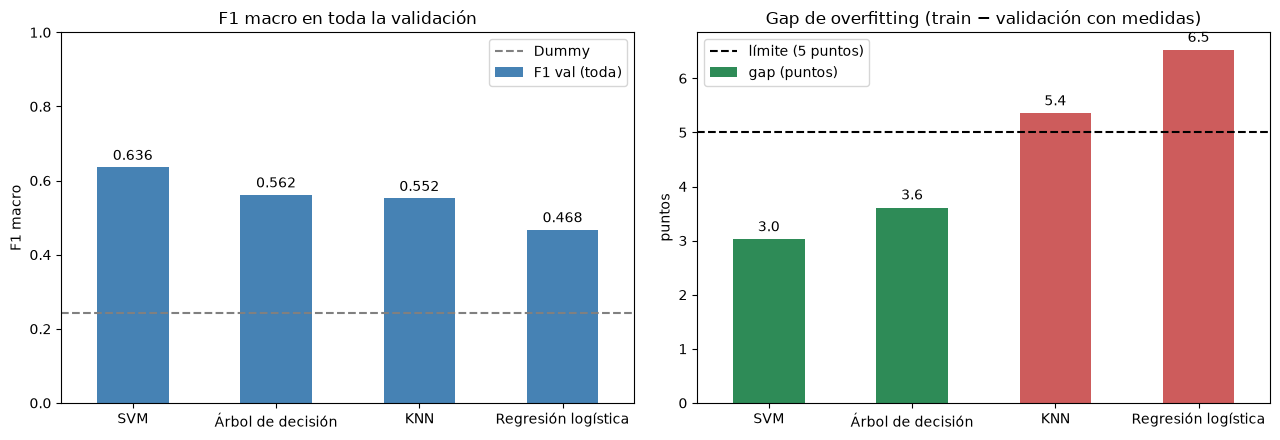

In [4]:
modelos = tabla_modelos.drop(index="Dummy (referencia)")
colores = [
    "seagreen" if g < GAP_MAXIMO else "indianred" for g in modelos["gap (puntos)"]
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
modelos["F1 val (toda)"].plot.bar(ax=ax1, color="steelblue", rot=0)
ax1.axhline(f1_dummy["toda la validación"], color="grey", ls="--", label="Dummy")
ax1.set(title="F1 macro en toda la validación", ylabel="F1 macro", ylim=(0, 1))
ax1.legend()
for i, v in enumerate(modelos["F1 val (toda)"]):
    ax1.text(i, v + 0.02, f"{v:.3f}", ha="center")

modelos["gap (puntos)"].plot.bar(ax=ax2, color=colores, rot=0)
ax2.axhline(GAP_MAXIMO, color="black", ls="--", label=f"límite ({GAP_MAXIMO} puntos)")
ax2.set(title="Gap de overfitting (train − validación con medidas)", ylabel="puntos")
ax2.legend()
for i, v in enumerate(modelos["gap (puntos)"]):
    ax2.text(i, v + 0.15, f"{v:.1f}", ha="center")
plt.tight_layout()
plt.show()

**Qué vemos:** el SVM es el más alto a la izquierda y tiene la barra verde más baja a la derecha. El árbol también cumple. El KNN y la regresión logística quedan en rojo, por encima de la línea de 5 puntos.

### 4.2 ¿Qué clases cuestan a todos?

**Qué hacemos:** un mapa de calor con el F1 de cada clase (columnas) para cada modelo (filas), en toda la validación.

**Por qué:** el F1 macro es una media de las cinco clases y esconde cuáles fallan. Si una clase sale mal en todos los modelos, el problema está en los datos y no en el algoritmo.

**Cómo leer el resultado:** azul oscuro es un F1 alto y claro es un F1 bajo. Hay que leer por columnas.

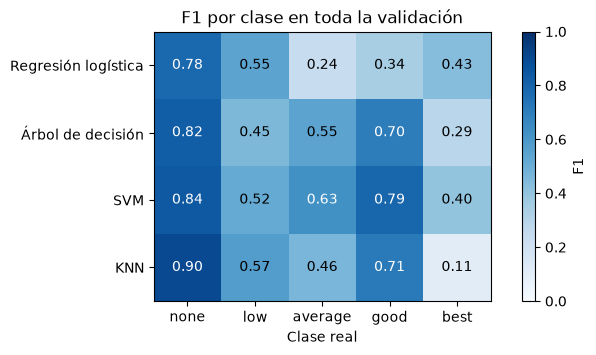

In [5]:
f1_clase = pd.DataFrame(
    {
        NOMBRES.get(n, n): {
            c: d["por_clase"]["toda la validación"][c]["f1"] for c in CLASES
        }
        for n, d in detalle.items()
    }
).T

fig, ax = plt.subplots(figsize=(8, 3.5))
imagen = ax.imshow(f1_clase, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASES)), CLASES)
ax.set_yticks(range(len(f1_clase)), f1_clase.index)
for i in range(f1_clase.shape[0]):
    for j in range(f1_clase.shape[1]):
        valor = f1_clase.iloc[i, j]
        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color="white" if valor > 0.6 else "black",
        )
ax.set(title="F1 por clase en toda la validación", xlabel="Clase real")
fig.colorbar(imagen, ax=ax, label="F1")
plt.show()

**Qué vemos:**

- **`none` es la clase más fácil** para todos (F1 de 0.78 a 0.90). La regla de las parcelas sin medidas ayuda mucho: esas parcelas siempre son `none`.
- **`best` es la más difícil** para todos (de 0.11 a 0.43). Los modelos la confunden con `good`, su vecina. Con 16 parcelas en validación y medidas muy parecidas a las de `good`, es difícil separarlas.
- `low` se queda en torno a 0.5 en todos los modelos.
- **El SVM es el mejor en `average` (0.63) y `good` (0.79)**, y el segundo en `best` (0.40, tras el 0.43 de la regresión logística). Por eso tiene el F1 macro más alto.

## Paso 5: elegir el modelo ganador

**Qué hacemos:** aplicamos la regla del equipo (`docs/acuerdos.md`): **entre los modelos con gap < 5, el de mayor F1 macro en toda la validación**. Como `cargar_resultados()` ya los ordena así, el ganador es el primero que cumple el gap. La celda lo comprueba otra vez para que nadie tenga que fiarse del orden.

**Por qué:** el ganador sale de una regla escrita antes de ver los resultados y de la validación, **nunca del test**. Elegir mirando el test es el error 4 de la guía: el test dejaría de ser una nota imparcial.

**Cómo leer el resultado:** el nombre del ganador y qué modelos quedan fuera y por qué.

In [6]:
cumplen = resultados[resultados["cumple_gap"]]
if cumplen.empty:
    raise ValueError(
        "Ningún modelo cumple el gap: no hay ganador según la regla del equipo."
    )

ganador = cumplen.index[0]
assert ganador == cumplen["f1_val"].idxmax(), (
    "El orden de cargar_resultados() no cuadra"
)

print(f"🏆 Modelo ganador: {NOMBRES.get(ganador, ganador)} ({ganador})")
print(f"   F1 macro en toda la validación: {resultados.loc[ganador, 'f1_val']:.3f}")
gap_ganador = resultados.loc[ganador, "gap"]
print(f"   Gap: {gap_ganador:.1f} puntos → {nivel_gap(gap_ganador)}")
print(f"   Hiperparámetros: {detalle[ganador]['hiperparametros']}")
print()
for nombre, r in resultados.drop(index=ganador).iterrows():
    motivo = (
        f"cumple el gap, pero su F1 es {r['f1_val']:.3f}"
        if r["cumple_gap"]
        else f"no cumple el gap ({r['gap']:.1f} puntos ≥ {GAP_MAXIMO})"
    )
    print(f"   {NOMBRES.get(nombre, nombre)}: {motivo}")

🏆 Modelo ganador: SVM (04_svm)
   F1 macro en toda la validación: 0.636
   Gap: 3.0 puntos → ✅ correcto
   Hiperparámetros: {'svm__C': 0.045}

   Árbol de decisión: cumple el gap, pero su F1 es 0.562
   KNN: no cumple el gap (5.4 puntos ≥ 5)
   Regresión logística: no cumple el gap (6.5 puntos ≥ 5)


**Por qué gana el SVM:**

1. **Cumple el gap**: 3.0 puntos (F1 train 0.631 y F1 en validación con medidas 0.601). Generaliza a datos que no vio en el entrenamiento.
2. **Es el de mayor F1 en toda la validación** entre los que cumplen: 0.636, frente al 0.562 del árbol. Son 7.4 puntos más, y supera al Dummy en 39 puntos.
3. **Es un modelo sencillo**: un SVM lineal con un solo hiperparámetro (`C = 0.045`, mucha regularización). Ese `C` tan bajo es lo que lo protege del sobreajuste.

**Por qué quedan fuera los demás:**

- **Árbol de decisión:** cumple el gap, pero tiene 7.4 puntos menos de F1 en validación.
- **KNN:** su F1 (0.552) es bueno, pero su gap es de 5.4 puntos. En su notebook se aceptó como un sobreajuste pequeño, pero la regla del equipo es estricta (< 5), así que no puede ganar.
- **Regresión logística:** tiene el F1 más bajo (0.468) y un gap de 6.5 puntos.

**Precauciones con el ganador (las dejamos escritas antes de ver el test):**

- En la CV su F1 varía mucho entre folds (0.582 ± 0.085). El árbol es mucho más estable (0.565 ± 0.025). En CV la diferencia entre los dos (1.7 puntos) es menor que esa variación, así que **no es seguro que el SVM sea mejor en cualquier muestra**. La regla decide por la validación, y ahí la ventaja sí es clara.
- **Por sitio** los dos quedan igual (SVM 0.507 y árbol 0.519, ambos con ± 0.11). Ninguno resuelve mejor los sitios nuevos.

## Paso 6: evaluación final en test (subtarea #65)

**Qué hacemos:** en **una sola celda**:

1. leemos el CSV de test, que ningún notebook había abierto antes;
2. cargamos el pipeline del ganador desde `models/`;
3. predecimos con la misma regla que la app: `predecir_con_regla()` responde `none` a las parcelas sin medidas sin preguntar al modelo (ADR-0001) y pasa el resto al pipeline;
4. calculamos las métricas en **todo el test** y **solo en las parcelas con medidas**, las métricas por clase y las dos matrices de confusión.

Como referencia, calculamos también el Dummy en test. `baseline_dummy()` llama «validación» a lo que recibe como segundo conjunto: **en esta celda, ese conjunto es el test**.

**Por qué:** el test simula los datos del mundo real. Se usa **una sola vez** y **solo con el ganador**. Si evaluáramos los cuatro modelos y nos quedáramos con el mejor en test, el test estaría eligiendo modelo y su nota dejaría de ser imparcial. El resto del notebook reutiliza las predicciones de esta celda y no vuelve a leer el CSV.

**Cómo leer el resultado:**
1. la tabla de métricas globales (F1 macro, accuracy, accuracy balanceada) y cuántos puntos supera al Dummy;
2. precision, recall y F1 de cada clase;
3. las matrices de confusión: la diagonal son los aciertos y lo que queda fuera son las confusiones (fila = clase real, columna = clase predicha).

Test: 111 parcelas; 8 sin medidas → «none» por la regla

Referencia: Dummy (aquí «validación» = test)
El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.186,0.360
solo con medidas,0.095,0.311


1. MÉTRICAS EN TEST (modelo ganador)


,F1 macro,accuracy,accuracy balanceada,supera Dummy (puntos)
todo el test,0.655,0.685,0.647,46.9
solo con medidas,0.643,0.660,0.634,54.8


2. MÉTRICAS POR CLASE EN TEST


todo el test                      solo con medidas               \
           precision recall    f1 soporte        precision recall    f1   
none            0.85   0.85  0.85    27.0             0.79   0.79  0.79   
low             0.54   0.44  0.48    16.0             0.54   0.44  0.48   
average         0.63   0.60  0.62    20.0             0.63   0.60  0.62   
good            0.64   0.78  0.70    32.0             0.64   0.78  0.70   
best            0.69   0.56  0.62    16.0             0.69   0.56  0.62   

                 
        soporte  
none       19.0  
low        16.0  
average    20.0  
good       32.0  
best       16.0

3. MATRICES DE CONFUSIÓN EN TEST


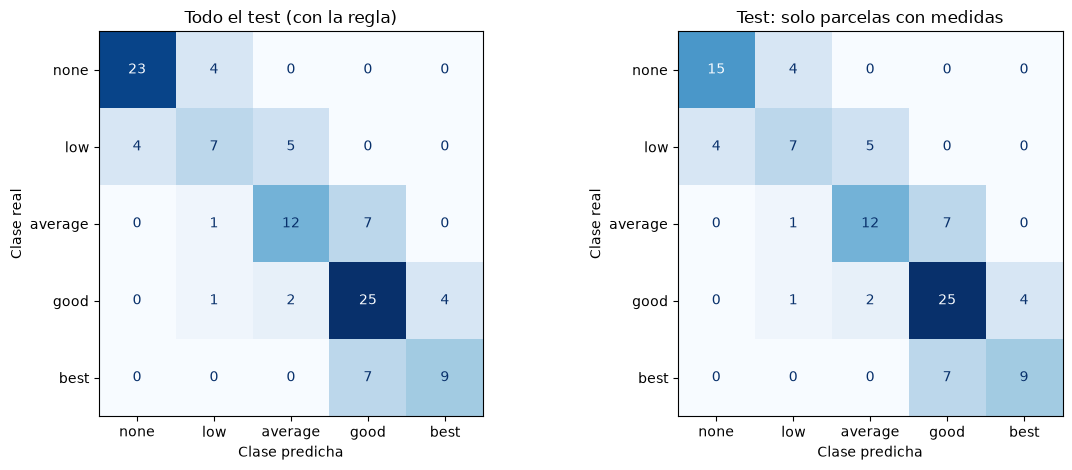

In [7]:
# ÚNICA lectura del test: una sola vez y solo con el modelo ganador
test = pd.read_csv(DATOS / "test.csv", encoding="utf-8")
X_test, y_test = separar_xy(test)
modelo = joblib.load(MODELOS / f"{ganador}.joblib")
variables = list(modelo.feature_names_in_)  # las columnas que usa el pipeline ganador

pred_test = predecir_con_regla(modelo, X_test[variables])
medidas_test = ~sin_medidas(X_test)
n_sin = (~medidas_test).sum()
print(f"Test: {len(y_test)} parcelas; {n_sin} sin medidas → «none» por la regla")

print("\nReferencia: Dummy (aquí «validación» = test)")
f1_dummy_test = baseline_dummy(X_train, y_train, X_test, y_test)

print("1. MÉTRICAS EN TEST (modelo ganador)")
metricas_test = pd.DataFrame(
    {
        "todo el test": metricas(y_test, pred_test),
        "solo con medidas": metricas(y_test[medidas_test], pred_test[medidas_test]),
    }
).T
metricas_test["supera Dummy (puntos)"] = 100 * (
    metricas_test["F1 macro"]
    - pd.Series(
        {
            "todo el test": f1_dummy_test["toda la validación"],
            "solo con medidas": f1_dummy_test["solo con medidas"],
        }
    )
)
display(metricas_test.round({"supera Dummy (puntos)": 1}).round(3))

print("2. MÉTRICAS POR CLASE EN TEST")
display(
    pd.concat(
        {
            "todo el test": por_clase(y_test, pred_test),
            "solo con medidas": por_clase(
                y_test[medidas_test], pred_test[medidas_test]
            ),
        },
        axis=1,
    ).round(2)
)

print("3. MATRICES DE CONFUSIÓN EN TEST")
_, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
dibujar_matriz(y_test, pred_test, "Todo el test (con la regla)", ejes[0])
dibujar_matriz(
    y_test[medidas_test],
    pred_test[medidas_test],
    "Test: solo parcelas con medidas",
    ejes[1],
)
plt.tight_layout()
plt.show()

**Qué vemos:**

- **F1 macro en test: 0.655** en todo el test y 0.643 solo con medidas, frente a un Dummy de 0.186 y 0.095. El modelo **supera al Dummy en 47 puntos** (55 solo con medidas). La accuracy es de 0.685 (0.660 con medidas).
- **Por clase:**
  - `none` es la mejor (F1 0.85). Las 8 parcelas sin medidas las acierta la regla.
  - `good` (0.70), `average` (0.62) y `best` (0.62) quedan en un nivel aceptable.
  - `low` es la más floja (0.48): recall de 0.44, se escapa más de la mitad de las parcelas `low`.
- **En las matrices**, casi todo lo que sale de la diagonal cae en la casilla de al lado: el modelo confunde clases vecinas (`best` con `good`, `average` con `good`, `low` con `average` o con `none`). Lo medimos en el paso 9.
- **Diferencia con validación:** en test `best` sube a un F1 de 0.62 (0.40 en validación). Con 16 parcelas, acertar 3 o 4 más cambia mucho la cifra: es variación de la muestra, no una mejora del modelo.

## Paso 7: ¿se parece el test a la validación?

**Qué hacemos:** ponemos juntas las métricas del ganador en **train**, **validación** y **test**, y calculamos el gap también con el test:

> gap en test = (F1 train − F1 test con medidas) × 100

**Por qué:** es la pregunta que hace la guía en el paso 8. Si el test cae mucho respecto a la validación, hubo **fuga de datos** o **sobreajuste a la validación** (por haber probado muchas cosas mirándola). Además, el gap en test comprueba el requisito de **overfitting < 5 %** con datos que no se usaron para nada.

**Cómo leer el resultado:** las filas de validación y test deberían tener cifras parecidas, y el gap en test debería ser menor de 5.

In [8]:
pred_val = predecir_con_regla(modelo, X_val[variables])
medidas_val = ~sin_medidas(X_val)
f1_train = f1_score(y_train, modelo.predict(X_train[variables]), average="macro")

comparacion = pd.DataFrame(
    {
        "train": metricas(y_train, modelo.predict(X_train[variables])),
        "validación (toda)": metricas(y_val, pred_val),
        "validación (con medidas)": metricas(y_val[medidas_val], pred_val[medidas_val]),
        "test (todo)": metricas(y_test, pred_test),
        "test (con medidas)": metricas(y_test[medidas_test], pred_test[medidas_test]),
    }
).T
display(comparacion.round(3))

assert abs(f1_train - detalle[ganador]["f1_train"]) < 1e-9, (
    "El modelo no es el del JSON"
)
gap_val = detalle[ganador]["gap"]
gap_test = 100 * (f1_train - comparacion.loc["test (con medidas)", "F1 macro"])
print(f"Gap en validación: {gap_val:.1f} puntos → {nivel_gap(gap_val)}")
print(f"Gap en test:       {gap_test:.1f} puntos → {nivel_gap(gap_test)}")

,F1 macro,accuracy,accuracy balanceada
train,0.631,0.657,0.617
validación (toda),0.636,0.709,0.631
validación (con medidas),0.601,0.663,0.603
test (todo),0.655,0.685,0.647
test (con medidas),0.643,0.660,0.634


Gap en validación: 3.0 puntos → ✅ correcto
Gap en test:       -1.1 puntos → ✅ correcto


**Qué vemos:**

- El F1 en **test (0.655) es incluso algo más alto que en validación (0.636)**, y lo mismo pasa solo con medidas (0.643 frente a 0.601). **No hay caída**, así que no hay señales de fuga ni de sobreajuste a la validación.
- **Gap en test: −1.1 puntos** (✅). Test y train quedan casi iguales: el modelo cumple el **overfitting < 5 %** también con datos nunca vistos.
- La pequeña subida respecto a validación es ruido de muestra: con ~110 parcelas, unas pocas parcelas mueven el F1 varios puntos. Lo esperable en producción es un F1 macro de **entre 0.60 y 0.65**.

### Preguntas de la guía (paso 8)

| Pregunta | Respuesta |
|---|---|
| ¿La métrica coincide con lo definido en el paso 0? | Sí: F1 macro, definida en `00_general`. Trata igual las cinco clases, aunque `good` sea la más frecuente. |
| ¿El resultado en test es parecido al de validación? | Sí: 0.655 frente a 0.636. No hay fuga ni sobreajuste. |
| ¿Rinde igual en todos los subgrupos? | Lo miramos por sitio en el paso siguiente. |
| ¿ROC-AUC, PR-AUC y calibración? | No se pueden calcular: el ganador es un SVM lineal (`SVC`) entrenado sin `probability=True`, así que solo da la clase y no probabilidades. Para la app basta con la clase. Si negocio necesitara un nivel de confianza, habría que reentrenar con probabilidades calibradas, y eso ya sería un modelo nuevo. |
| ¿Cambiamos de modelo por lo que sale en test? | **No.** El test solo informa. Elegir mirándolo sería el error 4 de la guía. |

## Paso 8: ¿rinde igual en todos los sitios?

**Qué hacemos:** separamos el test por sitio (`Abbrev`) y calculamos, para cada uno, cuántas parcelas hay, la accuracy y el F1 macro.

**Por qué:** la guía pide comprobar si el modelo rinde igual en todos los **subgrupos**. Aquí el subgrupo natural es el sitio: el EDA mostró que la clase depende mucho de dónde se plantó (ADR-0002), y la validación por sitio ya daba cifras más bajas.

**Cómo leer el resultado:** **cuidado con el tamaño**. Hay sitios con 2 a 9 parcelas, y ahí un solo acierto mueve la accuracy más de 10 puntos. El F1 macro por sitio es todavía menos fiable, porque en cada sitio solo aparecen algunas de las clases. Hay que buscar sitios con muchas parcelas y muchos errores, no fijarse en los extremos.

In [9]:
por_sitio = (
    pd.DataFrame({"sitio": X_test["Abbrev"], "real": y_test, "predicha": pred_test})
    .groupby("sitio")
    .apply(
        lambda g: pd.Series(
            {
                "parcelas": len(g),
                "clases distintas": g["real"].nunique(),
                "errores": int((g["real"] != g["predicha"]).sum()),
                "accuracy": accuracy_score(g["real"], g["predicha"]),
                "F1 macro": f1_score(g["real"], g["predicha"], average="macro"),
            }
        ),
        include_groups=False,
    )
    .sort_values("parcelas", ascending=False)
)
por_sitio.astype({"parcelas": int, "clases distintas": int, "errores": int}).round(2)

,parcelas,clases distintas,errores,accuracy,F1 macro
sitio,,,,,
Puk,19,4,6,0.68,0.52
Paw,14,4,5,0.64,0.28
K82,9,4,4,0.56,0.42
Wai,9,4,2,0.78,0.66
Wak,9,4,4,0.56,0.37
Lon,8,3,3,0.62,0.37
Mor,8,1,0,1.00,1.00
WSp,8,3,3,0.62,0.58
K83,7,3,2,0.71,0.50


**Qué vemos:**

- **Mor y Cra: 100 % de aciertos.** Las 8 parcelas de Mor en test son parcelas sin medidas: las resuelve la regla `none`, no el modelo.
- **Los sitios grandes**, Puk (19 parcelas) y Paw (14), tienen una accuracy de 0.68 y 0.64, cerca de la media (0.68). Paw tiene un F1 macro bajo (0.28) porque mezcla varias clases vecinas que el modelo confunde.
- **K82, Wak y Lon** quedan por debajo (accuracy de 0.56 a 0.63). Nga (2 parcelas, 0 aciertos) no permite sacar conclusiones.
- **Conclusión:** el modelo **no rinde igual en todos los sitios**, como ya anunciaba la validación por sitio (0.507 ± 0.108). Para un sitio nuevo hay que esperar más error que la media. Lo recogemos en los límites.

## Paso 9: análisis de errores e interpretación del ganador

### 9.1 ¿Qué errores comete?

**Qué hacemos:** `errores_frecuentes()` cuenta las confusiones (real → predicha) en todo el test y calcula a cuántas clases de distancia está cada error en la escala `none` < `low` < `average` < `good` < `best`.

**Por qué:** el enunciado pide un **análisis de errores**. Las clases tienen orden, así que no es lo mismo confundir `best` con `good` (clases vecinas) que con `low` (dos clases de distancia, un error grave).

**Cómo leer el resultado:** la frase de arriba resume cuántos errores son entre vecinas y cuántos graves. La tabla muestra las confusiones más frecuentes.

In [10]:
errores_frecuentes(y_test, pred_test)

Errores: 35 de 111. Entre clases vecinas: 34; a 2 o más clases de distancia: 1.


,real,predicha,parcelas,distancia
0,average,good,7,1
1,best,good,7,1
2,low,average,5,1
3,low,none,4,1
4,good,best,4,1
5,none,low,4,1
6,good,average,2,1
7,good,low,1,2
8,average,low,1,1


**Qué vemos:**

- **35 errores en 111 parcelas, y 34 son entre clases vecinas.** Solo hay **1 error grave**: una parcela `good` que el modelo predijo `low`. Cuando se equivoca, casi siempre se queda a un paso de la clase real.
- Las dos confusiones más frecuentes acaban en `good`: **`average` → `good` (7)** y **`best` → `good` (7)**. `good` es la clase más frecuente y el modelo tiende a ir hacia ella cuando duda.
- `low` → `none` (4) y `none` → `low` (4): en la parte baja de la escala, las parcelas `low` y las `none` con medidas se parecen.

**¿Qué datos ayudarían a corregirlos?** Más parcelas de `best` y `low`, y medidas que distingan un buen lote de uno excelente (por ejemplo, crecimiento en varios años). Las seis medidas actuales son puntuaciones de 1 a 5 o porcentajes, que separan poco las clases altas.

### 9.2 ¿En qué variables se apoya?

**Qué hacemos:** `importancia_permutacion()` desordena cada variable en las parcelas con medidas del test y mide cuánto cae el F1 macro. Es el mismo método que usó el SVM en su notebook (8.1), allí con validación.

**Por qué:** el enunciado pide **feature importance**, y la guía pregunta si el modelo se apoya en variables con sentido. Si en test sale el mismo orden que en validación, la interpretación es estable.

**Cómo leer el resultado:** cuanto más larga es la barra, más se apoya el modelo en esa variable.

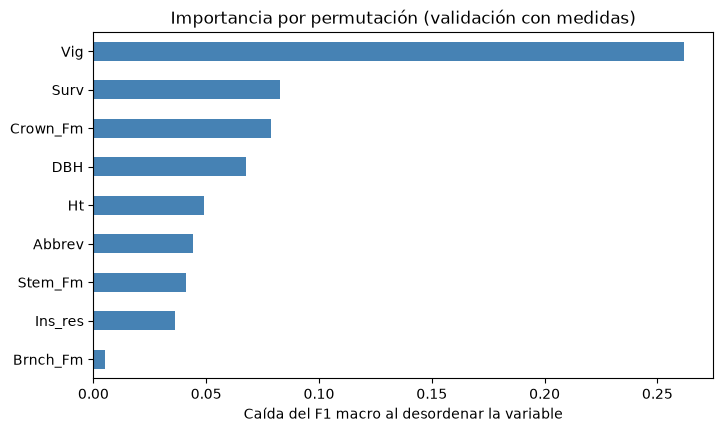

,importancia
Vig,0.262
Surv,0.083
Crown_Fm,0.079
DBH,0.068
Ht,0.049
Abbrev,0.044
Stem_Fm,0.041
Ins_res,0.036
Brnch_Fm,0.005


In [11]:
importancia = importancia_permutacion(modelo, X_test[variables], y_test)
display(importancia.sort_values(ascending=False).to_frame("importancia").round(3))

**Qué vemos:**

- **El vigor (`Vig`) es, con mucha diferencia, la variable más importante** (0.26), igual que en validación (0.265). Lo siguen la supervivencia (`Surv`), la forma de la copa (`Crown_Fm`), el diámetro (`DBH`) y la altura (`Ht`), todas entre 0.05 y 0.08.
- El **sitio** (`Abbrev`) pesa poco (0.04). El modelo decide sobre todo por cómo crecen los árboles, no por el lugar.
- El orden coincide en lo esencial con el de validación (`Vig` primero y `Surv` segundo). Respecto a validación, `Crown_Fm` sube y `Ht` baja. **Tiene sentido**: un lote vigoroso que sobrevive bien es el que más sirve para conservar el suelo, y eso cuadra con el EDA. El modelo no ha aprendido nada absurdo.

## Paso 10: requisitos del Nivel Esencial

**Qué hacemos:** repasamos los requisitos del enunciado (`docs/business/EXERCISE_SPECS.md`, Nivel Esencial) y decimos dónde se cumple cada uno.

**Por qué:** esta tabla sirve de base para el informe técnico (#46) y para las presentaciones (#47, #48).

| Requisito | Estado | Dónde |
|---|---|---|
| Modelo de clasificación multiclase funcional (mínimo 3 clases) | ✅ | 5 clases. Cuatro modelos entrenados (`02`–`05`); ganador: SVM (`models/04_svm.joblib`) |
| EDA con visualizaciones para clasificación (histogramas por clase, correlación…) | ✅ | `01_eda.ipynb` y `docs/informe-eda.md` |
| Overfitting < 5 % entre training y validation | ✅ | Gap del ganador: 3.0 puntos en validación y −1.1 en test (pasos 5 y 7) |
| Aplicación básica (Streamlit) | ⏳ | Pendiente (#43, #44, #45). Cargará `models/04_svm.joblib` |
| Informe: accuracy global | ✅ | Pasos 3 y 6 (0.685 en test) |
| Informe: precision, recall y F1 por clase | ✅ | Paso 6 (test) y notebooks `02`–`05` (validación) |
| Informe: matriz de confusión | ✅ | Paso 6, con y sin las parcelas sin medidas |
| Informe: feature importance | ✅ | Paso 9.2 y cada notebook de modelo |
| Informe: análisis de errores | ✅ | Paso 9.1 (errores entre vecinas y graves) y paso 8 (por sitio) |

## Conclusiones

### Para negocio

- El modelo elegido, un **SVM lineal**, **acierta la utilidad de 2 de cada 3 lotes** (accuracy de 0.685 en test). Su F1 macro (0.655) **multiplica por tres el del Dummy** (0.186). El Dummy representa responder siempre lo más habitual.
- **Cuando falla, casi siempre se queda a un paso**: 34 de 35 errores son entre clases vecinas. En la práctica, el modelo sirve para separar **lotes que no valen** (`none`/`low`) de **lotes que valen** (`good`/`best`) con bastante seguridad.
- **Su punto débil es distinguir `best` de `good`**, que es la confusión más frecuente junto con `average` → `good`. Para un programa de conservación, confundir `best` con `good` cuesta poco, porque los dos lotes son útiles. Lo que más preocuparía, recomendar un lote `none` o `low` como `good`/`best`, **no ha pasado ni una vez en test**.
- Las parcelas **sin medidas** se clasifican `none` con una regla fija. En validación y en test todas eran `none`, así que la regla no ha fallado nunca.

### Límites

- **Pocos datos:** 469 parcelas para entrenar y ~110 en validación y en test. Unas pocas parcelas mueven el F1 varios puntos. Por eso el F1 del SVM varía tanto entre folds de la CV (± 0.085).
- **Efecto del sitio:** con sitios que no ha visto, el modelo rinde peor (0.507 en la validación por sitio) y de forma desigual (paso 8). Para un sitio nuevo hay que esperar más errores que la media.
- **SVM frente al árbol:** el SVM gana con claridad en validación (+7.4 puntos), pero en la CV la diferencia (1.7 puntos) queda dentro de la variación. El árbol es más estable y más fácil de explicar (reglas). Si negocio prefiriera un modelo explicable, sería una alternativa razonable, aunque la regla del equipo elige el SVM.
- **Sin probabilidades:** el modelo da la clase pero no un nivel de confianza (paso 7).

### Despliegue y monitoreo (guía, paso 10)

| Pregunta | Respuesta |
|---|---|
| ¿Cómo sabremos que el modelo empieza a fallar? | Comparando sus predicciones con la utilidad real cuando se conozca (tras evaluar los ensayos). Si el F1 macro de un lote nuevo de parcelas baja claramente de 0.50 (la media de la CV menos su desviación: 0.582 − 0.085), hay que revisar. También hay que vigilar las medidas de entrada (por ejemplo, el vigor medio) por si cambian respecto a las de entrenamiento (*data drift*). |
| ¿Cada cuánto hay que reentrenar? | Cuando haya ensayos de **sitios nuevos** o se acumulen bastantes parcelas nuevas (del orden de cien), porque el sitio es lo que más mueve el resultado. |
| ¿Qué pasa si se equivoca? ¿Hay revisión humana? | Recomendamos que una persona experta revise los lotes que el modelo clasifica como `best` antes de dar una recomendación definitiva, porque es la clase que más confunde con `good`. Las parcelas sin medidas las resuelve la regla, y la app lo indica. |

### Siguientes pasos

1. **App (#43–#45):** carga `models/04_svm.joblib` y predice con la misma regla (`predecir_con_regla`), con TDD en `tests/`.
2. **Informe técnico (#46)** y **presentaciones (#47, #48)**: parten de este notebook (pasos 3, 6, 9 y 10).
3. **Notebook final (#66):** en la entrega, `python unir_notebooks.py` junta `00`–`06` en `final.ipynb`.